Libraries imported successfully!
Dataset extracted successfully!
Total speech files found: 2880
Feature extraction completed!
Feature shape: (2880, 80)
Training samples: 2304
Testing samples: 576
Feature scaling completed!

Training: KNN
Accuracy: 76.22 %

Training: SVM
Accuracy: 95.83 %

Training: Random Forest
Accuracy: 93.4 %

MODEL COMPARISON
           Model  Accuracy
0            KNN  0.762153
1            SVM  0.958333
2  Random Forest  0.934028


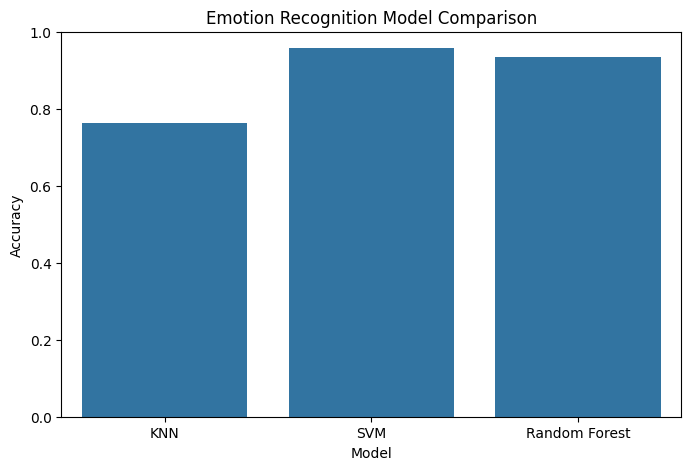


Best Model: SVM

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Neutral       0.86      0.95      0.90        38
        Calm       0.95      0.97      0.96        76
       Happy       0.97      0.97      0.97        77
         Sad       1.00      0.90      0.95        77
       Angry       1.00      0.95      0.97        77
     Fearful       0.95      0.95      0.95        77
     Disgust       0.95      0.97      0.96        77
   Surprised       0.95      1.00      0.97        77

    accuracy                           0.96       576
   macro avg       0.95      0.96      0.95       576
weighted avg       0.96      0.96      0.96       576



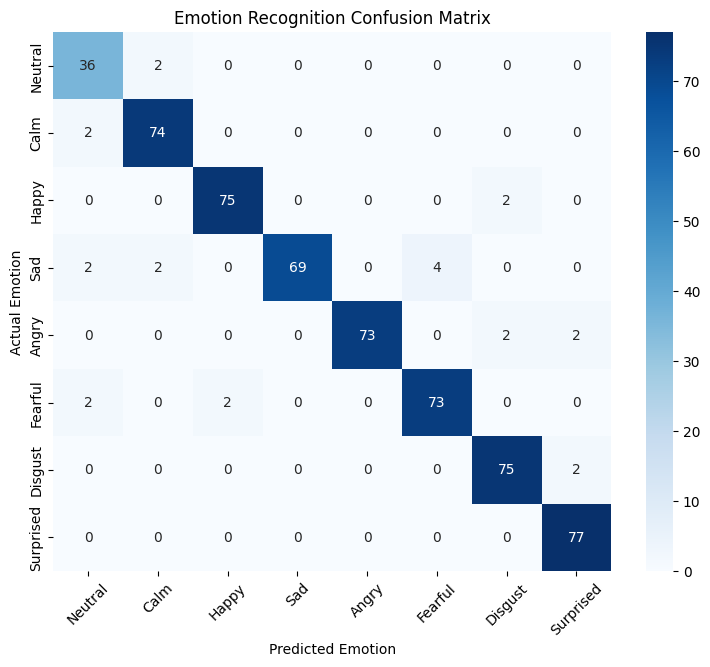

Model and scaler saved successfully!

Upload a WAV speech recording


In [ ]:

# =====

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
=====================================
# TASK 2: EMOTION RECOGNITION FROM SPEECH
# Dataset: RAVDESS
# Algorithms: KNN, SVM, Random Forest
# Features: MFCC
# ==========================================

!pip -q install librosa soundfile scikit-learn seaborn

import os
import zipfile
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

# STEP 1: EXTRACT DATASET

ZIP_PATH = "/content/archive.zip"
EXTRACT_DIR = "/content/RAVDESS"

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError("archive.zip not found in /content")

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")

# STEP 2: DEFINE EMOTIONS

emotion_dict = {
    "01": "Neutral",
    "02": "Calm",
    "03": "Happy",
    "04": "Sad",
    "05": "Angry",
    "06": "Fearful",
    "07": "Disgust",
    "08": "Surprised"
}

# STEP 3: FIND AUDIO FILES

audio_files = []

for root, dirs, files_list in os.walk(EXTRACT_DIR):
    for file in files_list:
        if file.lower().endswith(".wav"):
            parts = file.split("-")

            if (len(parts) == 7 and
                parts[0] == "03" and
                parts[1] == "01" and
                parts[2] in emotion_dict):

                audio_files.append(
                    (os.path.join(root, file), parts[2])
                )

print("Total speech files found:", len(audio_files))

if len(audio_files) == 0:
    raise ValueError(
        "No matching speech files found. Check whether archive.zip "
        "contains the RAVDESS Audio-only Speech dataset."
    )

# STEP 4: EXTRACT MFCC FEATURES

def extract_features(file_path):

    audio, sr = librosa.load(
        file_path,
        sr=22050,
        duration=4
    )

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=40
    )

    mean = np.mean(mfcc, axis=1)
    std = np.std(mfcc, axis=1)

    return np.concatenate([mean, std])


X = []
y = []

for file_path, emotion in audio_files:

    try:
        features = extract_features(file_path)
        X.append(features)
        y.append(emotion)

    except Exception as e:
        print("File skipped:", file_path, e)

X = np.array(X)
y = np.array(y)

print("Feature extraction completed!")
print("Feature shape:", X.shape)

# STEP 5: SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# STEP 6: FEATURE SCALING

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed!")

# STEP 7: TRAIN MODELS

models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),

    "SVM": SVC(
        kernel="rbf",
        C=10,
        gamma="scale"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

results = {}
    accuracy = accuracy_score(y_test, predictions)

    results[name] = accuracy

    print("Accuracy:", round(accuracy * 100, 2), "%")

# STEP 8: COMPARE MODELS

results_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Accuracy": list(results.values())
})

print("\nMODEL COMPARISON")
print(results_df)

plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.title("Emotion Recognition Model Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

# STEP 9: SELECT BEST MODEL

best_name = max(results, key=results.get)
best_model = models[best_name]

print("\nBest Model:", best_name)

y_pred = best_model.predict(X_test)

# STEP 10: CLASSIFICATION REPORT

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    labels=list(emotion_dict.keys()),
    target_names=list(emotion_dict.values()),
    zero_division=0
))

# STEP 11: CONFUSION MATRIX

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(emotion_dict.keys())
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=list(emotion_dict.values()),
    yticklabels=list(emotion_dict.values())
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Emotion Recognition Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

# STEP 12: SAVE MODEL

joblib.dump(best_model, "/content/emotion_model.joblib")
joblib.dump(scaler, "/content/emotion_scaler.joblib")

print("Model and scaler saved successfully!")

# STEP 13: TEST A NEW AUDIO RECORDING

from google.colab import files

print("\nUpload a WAV speech recording")

uploaded = files.upload()

if uploaded:

    audio_path = next(iter(uploaded.keys()))

    new_features = extract_features(audio_path)
    new_features = new_features.reshape(1, -1)

    new_features = scaler.transform(new_features)

    prediction = best_model.predict(new_features)[0]

    print("\nPREDICTED EMOTION:",
          emotion_dict[prediction])

print("\nTASK 2 COMPLETED SUCCESSFULLY!")
